# Differential usage: transcript isoforms and ORFs

One objective: for genes whose isoform mix may differ between the groups, show the share each isoform takes in every sample. The tests are the DRIMSeq tables from S4.

In [1]:
source("src/heatmap.R")   # read_groups
source("src/usage.R")
options(repr.plot.width = 11, repr.plot.height = 7)
results_dir <- "../LRP2_test_results"   # change to the results folder of the run
comparison  <- "HepG2_vs_K562"          # prefix of the S4 files
groups <- read_groups(file.path(results_dir, paste0(comparison, ".lr_leafcutter.groups_file.txt")))

**Explanation.** Two lines to change for another run, as in the other notebooks. DRIMSeq asks a different question from the volcano plots: not whether a gene is expressed more, but whether it spends its expression on different isoforms.

In [2]:
dtu <- prepare_usage(read_usage(file.path(results_dir, paste0(comparison, "_DTU_transcript_DRIMSeq_summary.txt"))), "transcript")
head(gene_usage_table(dtu), 10)

,gene,adj_p
,<chr>,<dbl>
3,CDC45,1.828765e-27
11,PPIL2,2.046277e-12
35,YDJC,4.350030e-03
60,PI4KA,2.700349e-02
15,GGT1,1.488150e-01
44,TANGO2,1.554172e-01
24,TOM1,3.650875e-01
27,TSPO,3.930363e-01
57,RTL10,4.325795e-01


**Explanation.** One row per gene with the adjusted p value of the usage test, most significant first. `NA` means DRIMSeq did not test that gene (too little expression, or fewer isoforms than the filters need).

Warning message:
“Removed 20 rows containing missing values or values outside the scale range
(`geom_col()`).”


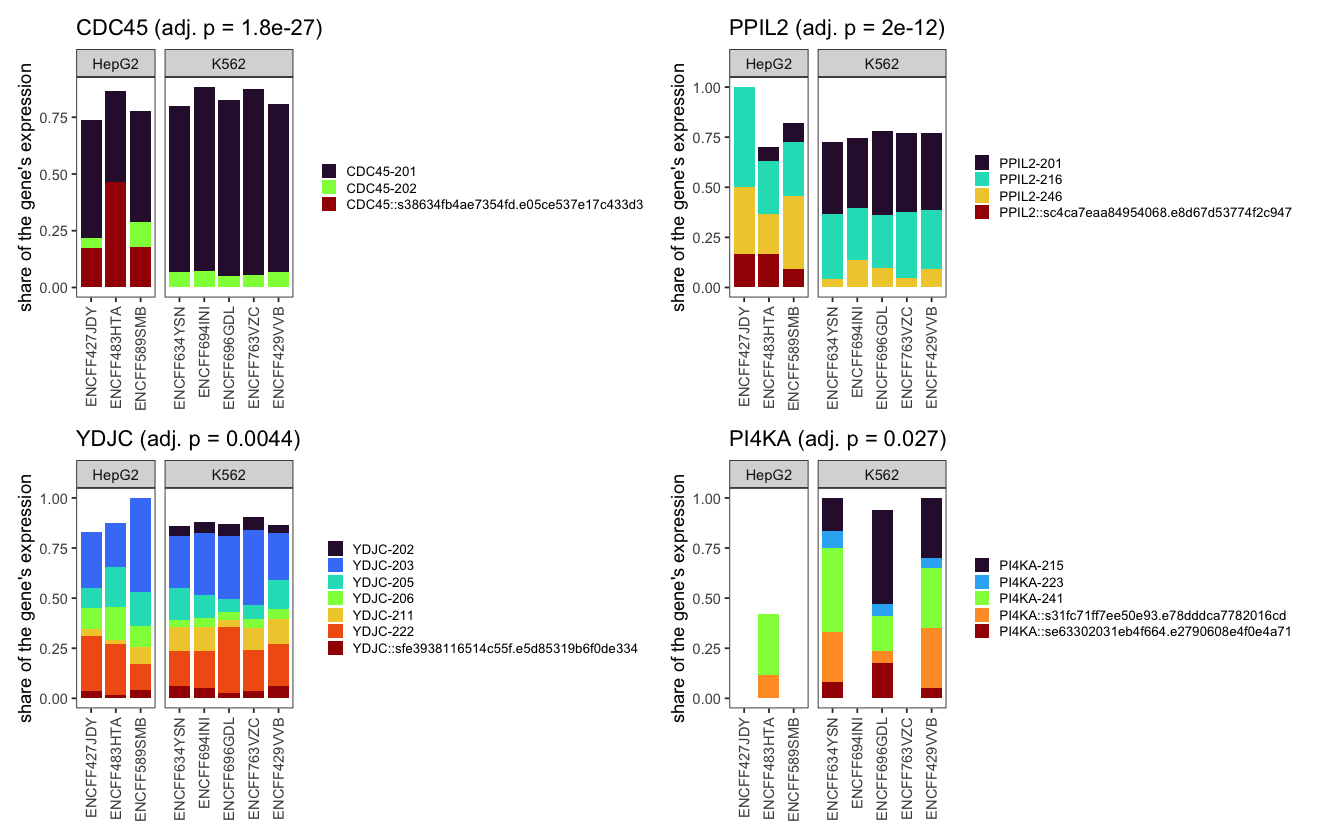

In [3]:
usage_panel(dtu, groups, n = 4)

**Explanation.** The four most significant genes. Each bar is a sample, split by group; the colours are the gene's isoforms and the bar height is the share of the gene's expression that isoform takes. If the colour pattern differs between the groups, the gene switches isoforms. A sample with no expression of the gene is left blank. Bars stop short of 1.0 because DRIMSeq drops very rare isoforms before testing; the missing part is those isoforms.

Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_col()`).”


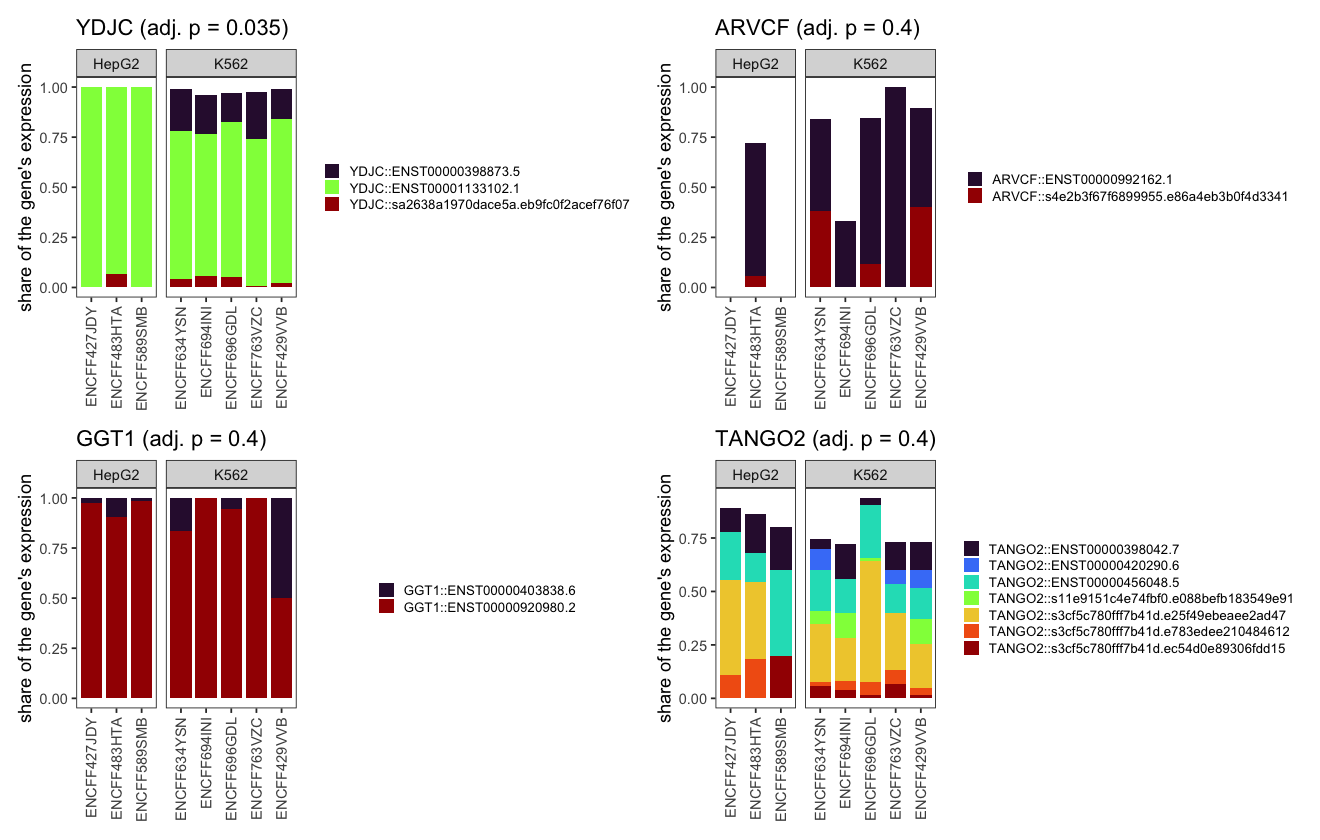

In [4]:
du_orf <- prepare_usage(read_usage(file.path(results_dir, paste0(comparison, "_DU_ORF_DRIMSeq_summary.txt"))), "orf")
usage_panel(du_orf, groups, n = 4)

**Explanation.** The same for open reading frames (ORFs): whether the predicted protein-coding versions of a gene are used differently between the groups.